# Experiment 5 — Data Visualization for AI Models
**Aim:** Translate English text to French using T5-small, evaluate with BLEU, and visualize the per-sentence scores.

### Dataset decision
The experiment sheet specifies English→French translation with T5-small and four reference translations. The cricket image dataset is not suitable for machine translation, so this notebook follows the prescribed translation dataset exactly. The BattingCoach repository is documented as the shared project context, not as an artificial translation corpus.

## 1. Install packages

In [25]:
from importlib.metadata import version

for package in ('transformers', 'torch', 'sacrebleu', 'matplotlib', 'pandas'):
    try:
        print(f"{package}: {version(package)}")
    except Exception as exc:
        print(f"{package}: unavailable ({exc})")


transformers: 5.22.1
torch: 2.15.0
sacrebleu: 2.6.0
matplotlib: 3.11.2
pandas: 3.1.0


## 2. Load T5-small

In [26]:
import torch, matplotlib.pyplot as plt, pandas as pd
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import sacrebleu
MODEL_NAME = "google-t5/t5-small"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
print("Model:", MODEL_NAME, "| device:", device)

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 487.20it/s]

Model: google-t5/t5-small | device: cpu


## 3. Define English sentences and French references

In [27]:
english = [
    "Hello, how are you?",
    "I love artificial intelligence.",
    "The weather is very good today.",
    "I am a computer science student."
]
references = [
    "Bonjour, comment allez-vous ?",
    "J'aime l'intelligence artificielle.",
    "Le temps est très beau aujourd'hui.",
    "Je suis étudiant en informatique."
]

## 4. Generate translations and calculate sentence BLEU

In [28]:
translations, scores = [], []
for source, reference in zip(english, references):
    prompt = "translate English to French: " + source
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True).to(device)
    with torch.no_grad():
        generated = model.generate(**inputs, max_new_tokens=50)
    french = tokenizer.decode(generated[0], skip_special_tokens=True)
    bleu = sacrebleu.sentence_bleu(french, [reference]).score
    translations.append(french); scores.append(bleu)
    print("\nEnglish:", source, "\nGenerated French:", french,
          "\nReference:", reference, "\nBLEU:", round(bleu,2))
results = pd.DataFrame({"English":english, "Reference French":references,
                        "Generated French":translations, "BLEU":scores})
results


English: Hello, how are you? 
Generated French: Bonjour, comment êtes-vous? 
Reference: Bonjour, comment allez-vous ? 
BLEU: 42.73

English: I love artificial intelligence. 
Generated French: Je m'aime l'intelligence artificielle. 
Reference: J'aime l'intelligence artificielle. 
BLEU: 39.76

English: The weather is very good today. 
Generated French: Le temps est très bon aujourd'hui. 
Reference: Le temps est très beau aujourd'hui. 
BLEU: 48.89

English: I am a computer science student. 
Generated French: Je suis étudiant en informatique. 
Reference: Je suis étudiant en informatique. 
BLEU: 100.0


,English,Reference French,Generated French,BLEU
0,"Hello, how are you?","Bonjour, comment allez-vous ?","Bonjour, comment êtes-vous?",42.728701
1,I love artificial intelligence.,J'aime l'intelligence artificielle.,Je m'aime l'intelligence artificielle.,39.763536
2,The weather is very good today.,Le temps est très beau aujourd'hui.,Le temps est très bon aujourd'hui.,48.892302
3,I am a computer science student.,Je suis étudiant en informatique.,Je suis étudiant en informatique.,100.000000


## 5. BLEU score chart data

In [29]:
x = range(1, len(scores)+1)

## 6. Bar plot

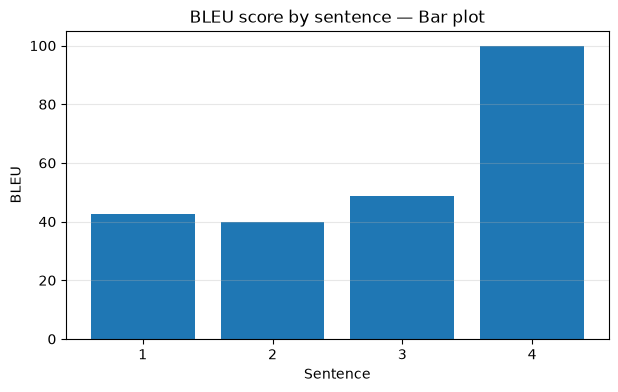

In [30]:
plt.figure(figsize=(7,4)); plt.bar(list(x), scores)
plt.title("BLEU score by sentence — Bar plot"); plt.xlabel("Sentence"); plt.ylabel("BLEU")
plt.xticks(list(x)); plt.grid(axis="y", alpha=.3); plt.show()

## 7. Line plot

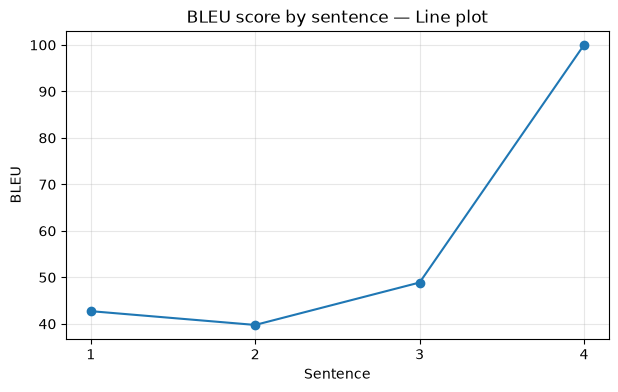

In [31]:
plt.figure(figsize=(7,4)); plt.plot(list(x), scores, marker="o")
plt.title("BLEU score by sentence — Line plot"); plt.xlabel("Sentence"); plt.ylabel("BLEU")
plt.xticks(list(x)); plt.grid(True, alpha=.3); plt.show()

## 8. Scatter plot

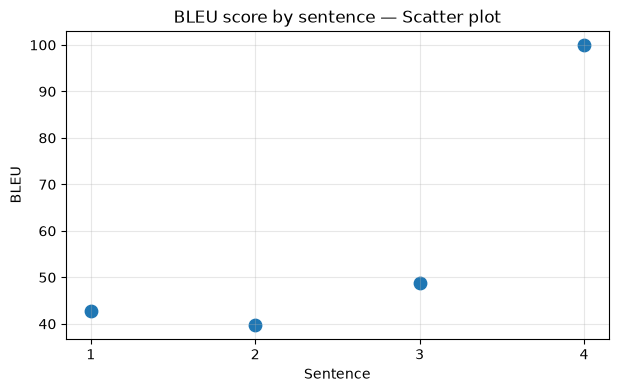

In [32]:
plt.figure(figsize=(7,4)); plt.scatter(list(x), scores, s=80)
plt.title("BLEU score by sentence — Scatter plot"); plt.xlabel("Sentence"); plt.ylabel("BLEU")
plt.xticks(list(x)); plt.grid(True, alpha=.3); plt.show()

## 9. Histogram

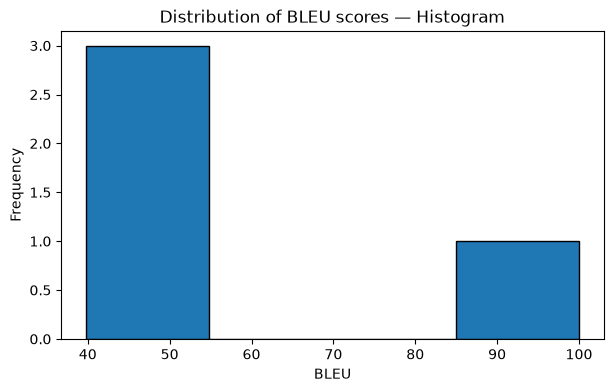

In [33]:
plt.figure(figsize=(7,4)); plt.hist(scores, bins=4, edgecolor="black")
plt.title("Distribution of BLEU scores — Histogram"); plt.xlabel("BLEU"); plt.ylabel("Frequency")
plt.show()

## 10. Box plot

C:\Users\nikhi\AppData\Local\Temp\ipykernel_20860\2319405413.py:1: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.figure(figsize=(5,4)); plt.boxplot(scores, vert=True)


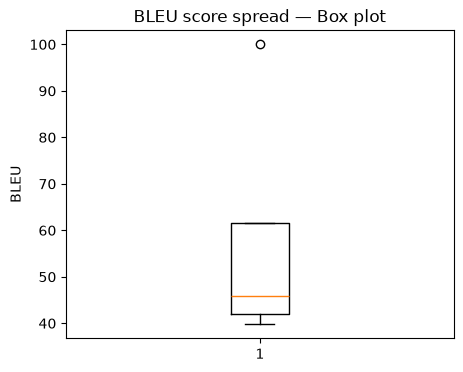

In [34]:
plt.figure(figsize=(5,4)); plt.boxplot(scores, vert=True)
plt.title("BLEU score spread — Box plot"); plt.ylabel("BLEU"); plt.show()

## 11. Area plot

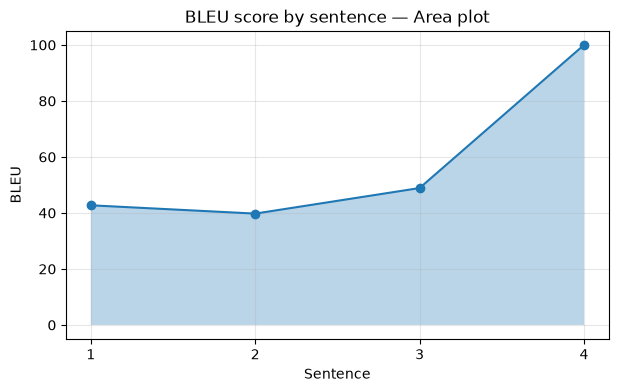

In [35]:
plt.figure(figsize=(7,4)); plt.fill_between(list(x), scores, alpha=.3)
plt.plot(list(x), scores, marker="o")
plt.title("BLEU score by sentence — Area plot"); plt.xlabel("Sentence"); plt.ylabel("BLEU")
plt.xticks(list(x)); plt.grid(True, alpha=.3); plt.show()

## 12. Overall score and conclusion

In [36]:
print("Mean sentence BLEU:", round(sum(scores)/len(scores),2))
print("Corpus BLEU:", round(sacrebleu.corpus_bleu(translations, [references]).score,2))

Mean sentence BLEU: 57.85
Corpus BLEU: 57.54


Interpret BLEU cautiously: it measures n-gram overlap and does not fully measure meaning or fluency. Record the model and exact candidate/reference strings used.